# **DATAFEST BCP 2026**
**Tema:** **Análisis de la variable objetivo — Propensión de conversión de clientes**

Integrantes:

-Peña Alvarez Sarita Anny

-Córdova Falcón Gabriel Alejandro

-Chinchay Paucar Anell Aracely

-Ortiz Ochochoque Analucia Heidy

-Cardenas Sikos Roxana Lizbeth

**Contenido:**
1. Cargar los datos (`train.csv`, `test.csv`, `sample_submission.csv`, `metaData.csv`) y validación de reglas
2. Análisis de `objetivo`: cantidad y probabilidad de 0 y 1
3. Análisis del desbalance de clases
4. Relación entre `objetivo` y variables numéricas (4.1: hallazgo sobre `dias_ultima_interaccion`)
5. Relación entre `objetivo` y variables (categóricas y booleanas)
6. Identificación de variables potencialmente importantes
7. Explicación de AUC y Gini
8. Comparación entre `train` y `test`
9. Modelo y archivo final (`submission.csv`)
10. Conclusiones

## 1. Cargar los datos
Usamos los 4 archivos proporcionados como base de datos: `train.csv`, `test.csv`, `sample_submission.csv` y `metaData.csv`. Además, seguimos las indicaciones del `DATASET_DESCRIPTION.md`, donde se indican las reglas.

In [1]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.metrics import roc_auc_score, roc_curve
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi'] = 100

ARCHIVOS = ['train.csv', 'test.csv', 'sample_submission.csv', 'metaData.csv']

# Ruta de los datos: se usa la primera carpeta donde estén los 4 archivos
# (Colab: sube los archivos a /content o monta Drive y agrega tu carpeta a la lista).
CANDIDATAS = ['.', '/content', '/content/drive/MyDrive', '/mnt/user-data/uploads']
RUTA = next((r for r in CANDIDATAS if all(os.path.exists(os.path.join(r, a)) for a in ARCHIVOS)), None)
assert RUTA is not None, f'No se encontraron los archivos {ARCHIVOS}. Ajusta la lista CANDIDATAS.'
print('Ruta de datos:', os.path.abspath(RUTA))

train  = pd.read_csv(os.path.join(RUTA, 'train.csv'))
test   = pd.read_csv(os.path.join(RUTA, 'test.csv'))
sample = pd.read_csv(os.path.join(RUTA, 'sample_submission.csv'))
meta   = pd.read_csv(os.path.join(RUTA, 'metaData.csv'))
for nombre, d in [('train', train), ('test', test), ('sample_submission', sample), ('metaData', meta)]:
    print(f'{nombre:18s} filas={d.shape[0]:>7,}  columnas={d.shape[1]}')

# Control: los archivos oficiales deben tener estas dimensiones (DATASET_DESCRIPTION.md)
assert train.shape == (110100, 25), f'train debería tener 110.100 filas y 25 columnas, tiene {train.shape}. ¿Archivo modificado?'
assert test.shape  == (9900, 24),   f'test debería tener 9.900 filas y 24 columnas, tiene {test.shape}.'
display(train.head())

Ruta de datos: /content
train              filas=110,100  columnas=25
test               filas=  9,900  columnas=24
sample_submission  filas=  9,900  columnas=2
metaData           filas=     26  columnas=4


,id_cliente,mes,edad,ingresos,ratio_deuda_ingresos,antiguedad_cuenta_meses,numero_productos,saldo_promedio,dias_ultima_transaccion,ocupacion,...,es_nuevo_cliente,tiene_prestamo,antiguedad_direccion_meses,visitas_web_ultimos_90_dias,distancia_sucursal_km,dispositivo_principal,dia_preferido_pago,tiene_seguro,dias_ultima_interaccion,objetivo
0,1,202601,26,42120.349663,0.367310,139,2,40949.765573,67,professional,...,False,False,222,10,9.898223,android,21,True,67,0
1,2,202601,56,89837.390440,0.338092,29,2,35233.622561,304,manager,...,False,False,58,2,9.311922,ios,20,True,304,0
2,3,202601,34,45951.715455,0.444587,21,2,39486.902998,220,clerical,...,False,False,8,6,12.188249,android,12,False,220,0
3,4,202601,62,54673.148516,0.243261,43,2,300.000000,110,manual,...,False,False,119,9,10.459796,ios,20,False,110,0
4,5,202601,37,100239.135609,0.230946,113,1,32066.808006,247,professional,...,False,False,25,6,36.502645,ios,13,False,247,1


### Revisión de diccionario de datos (`metaData.csv`) y validación de las reglas del dataset
Vemos las reglas importantes que se verifican a continuación:
un cliente con `objetivo = 1` no vuelve a aparecer en meses posteriores, y el test es un único mes posterior al train.

In [2]:
pd.set_option('display.max_colwidth', 120)
display(meta)

cols_meta = set(meta.column_name) - {'prediccion'}
conv_mes = train[train.objetivo == 1].groupby('id_cliente').mes.min().rename('mes_conv')
tmp = train.merge(conv_mes, on='id_cliente')
checks = {
    'train tiene exactamente las columnas descritas en metaData':      set(train.columns) == cols_meta,
    'test = columnas de train sin `objetivo`':                        list(test.columns) == [c for c in train.columns if c != 'objetivo'],
    'sample_submission tiene columnas id_cliente, prediccion':        list(sample.columns) == ['id_cliente', 'prediccion'],
    'sin valores faltantes en train ni test':                         int(train.isna().sum().sum() + test.isna().sum().sum()) == 0,
    'test corresponde a un único mes':                                test.mes.nunique() == 1,
    'test es posterior al último mes de train':                       test.mes.min() > train.mes.max(),
    'sample_submission tiene los mismos id_cliente y orden que test': bool((sample.id_cliente.values == test.id_cliente.values).all()),
    'un cliente convertido no reaparece en meses posteriores (train)': int((tmp.mes > tmp.mes_conv).sum()) == 0,
    'ningún cliente convertido en train aparece en test':             not test.id_cliente.isin(conv_mes.index).any(),
}
for k, v in checks.items(): print(('OK   ' if v else 'FALLA'), k)
print()
print('Meses en train:', [int(m) for m in sorted(train.mes.unique())], '| mes en test:', [int(m) for m in sorted(test.mes.unique())])

,column_name,description,type,notes
0,id_cliente,Identificador único del cliente,int,Un cliente puede aparecer en varios meses y si tiene objetivo 1 no vuelve a aparecer en meses posteriores.
1,mes,Mes calendario en formato AAAAMM,int,El split temporal se realiza por ventana mensual; el test suele ser el mes más reciente y suele ser un único mes.
2,edad,Edad del cliente,int,Variable numérica
3,ingresos,Ingresos anuales,float,Variable numérica
4,ratio_deuda_ingresos,Ratio de deuda sobre ingresos,float,Variable numérica
5,antiguedad_cuenta_meses,Antigüedad de la cuenta del cliente en meses,int,Variable numérica
6,numero_productos,Número de productos bancarios activos del cliente,int,Variable numérica
7,saldo_promedio,Saldo promedio de la cuenta,float,Variable numérica
8,dias_ultima_transaccion,Días desde la última transacción,int,Variable numérica
9,ocupacion,Categoría laboral del cliente,string,Variable categórica


OK    train tiene exactamente las columnas descritas en metaData
OK    test = columnas de train sin `objetivo`
OK    sample_submission tiene columnas id_cliente, prediccion
OK    sin valores faltantes en train ni test
OK    test corresponde a un único mes
OK    test es posterior al último mes de train
OK    sample_submission tiene los mismos id_cliente y orden que test
OK    un cliente convertido no reaparece en meses posteriores (train)
OK    ningún cliente convertido en train aparece en test

Meses en train: [202601, 202602, 202603, 202604, 202605, 202606, 202607, 202608, 202609, 202610, 202611] | mes en test: [202612]


In [3]:
TARGET = 'objetivo'
ids = ['id_cliente', 'mes']
bool_cols = [c for c in train.columns if train[c].dtype == bool]
cat_cols  = [c for c in train.columns if c not in bool_cols + ids + [TARGET] and not pd.api.types.is_numeric_dtype(train[c])]
num_cols  = [c for c in train.columns if c not in bool_cols + cat_cols + ids + [TARGET]]
print('Numéricas  :', num_cols); print('Categóricas:', cat_cols); print('Booleanas  :', bool_cols)
assert len(bool_cols) == 5 and len(cat_cols) == 5, 'Se esperaban 5 booleanas y 5 categóricas'
print('\nValores faltantes totales (train + test):', int(train.isna().sum().sum() + test.isna().sum().sum()))
train[bool_cols] = train[bool_cols].astype(int)
test[bool_cols]  = test[bool_cols].astype(int)

Numéricas  : ['edad', 'ingresos', 'ratio_deuda_ingresos', 'antiguedad_cuenta_meses', 'numero_productos', 'saldo_promedio', 'dias_ultima_transaccion', 'antiguedad_direccion_meses', 'visitas_web_ultimos_90_dias', 'distancia_sucursal_km', 'dia_preferido_pago', 'dias_ultima_interaccion']
Categóricas: ['ocupacion', 'region', 'canal_adquisicion', 'banda_riesgo', 'dispositivo_principal']
Booleanas  : ['tiene_tarjeta_credito', 'activo_movil', 'es_nuevo_cliente', 'tiene_prestamo', 'tiene_seguro']

Valores faltantes totales (train + test): 0


## 2. Análisis de la variable `objetivo`

,cantidad,porcentaje (%)
objetivo,,
0,93533.0,84.95
1,16567.0,15.05
Total,110100.0,100.00


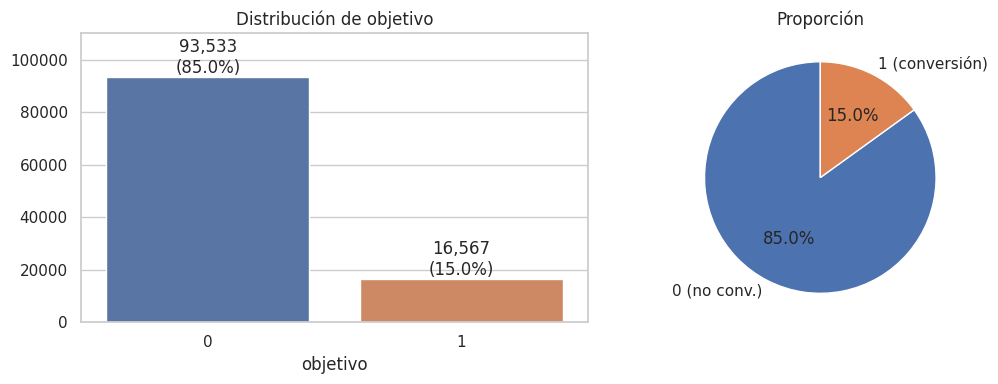

In [4]:
conteo = train[TARGET].value_counts().sort_index()
tabla = pd.DataFrame({'cantidad': conteo, 'porcentaje (%)': (conteo / len(train) * 100).round(2)})
tabla.loc['Total'] = [len(train), 100.0]
display(tabla)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x=conteo.index, y=conteo.values, ax=ax[0], palette=['#4C72B0', '#DD8452'])
for i, v in enumerate(conteo.values): ax[0].text(i, v, f'{v:,}\n({v/len(train):.1%})', ha='center', va='bottom')
ax[0].set_title('Distribución de objetivo'); ax[0].set_ylim(0, conteo.max() * 1.18)
ax[1].pie(conteo.values, labels=['0 (no conv.)', '1 (conversión)'], autopct='%1.1f%%', colors=['#4C72B0', '#DD8452'], startangle=90)
ax[1].set_title('Proporción'); plt.tight_layout(); plt.show()

### Evolución mensual de la tasa de conversión

,observaciones,conversiones,tasa
mes,,,
202601,10400,1521,14.62
202602,9800,1543,15.74
202603,10300,1527,14.83
202604,9600,1473,15.34
202605,10100,1584,15.68
202606,10350,1600,15.46
202607,9700,1410,14.54
202608,10050,1449,14.42
202609,9900,1393,14.07


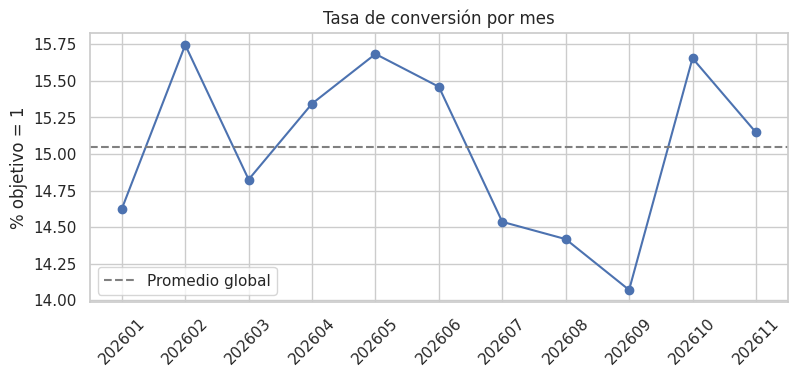

Clientes únicos en train: 24628 | clientes únicos en test: 9900
Meses por cliente (train):
count    24628.00
mean         4.47
std          3.17
min          1.00
25%          2.00
50%          4.00
75%          6.00
max         11.00
dtype: float64
Clientes con más de una conversión (debería ser 0): 0
Variables que cambian de un mes a otro para un mismo cliente: ['dias_ultima_interaccion']


In [5]:
m = train.groupby('mes')[TARGET].agg(['size', 'sum', 'mean']).rename(columns={'size': 'observaciones', 'sum': 'conversiones', 'mean': 'tasa'})
display(m.assign(tasa=(m.tasa * 100).round(2)))
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(m.index.astype(str), m.tasa * 100, marker='o'); ax.axhline(train[TARGET].mean() * 100, ls='--', c='gray', label='Promedio global')
ax.set_ylabel('% objetivo = 1'); ax.set_title('Tasa de conversión por mes'); ax.legend(); plt.xticks(rotation=45); plt.show()

# Estructura cliente-mes
print('Clientes únicos en train:', train.id_cliente.nunique(), '| clientes únicos en test:', test.id_cliente.nunique())
print('Meses por cliente (train):'); print(train.groupby('id_cliente').size().describe().round(2))
print('Clientes con más de una conversión (debería ser 0):', int((train.groupby('id_cliente')[TARGET].sum() > 1).sum()))
var_cliente = train.drop(columns=['mes', TARGET]).groupby('id_cliente').nunique().max()
print('Variables que cambian de un mes a otro para un mismo cliente:', var_cliente[var_cliente > 1].index.tolist())

## 3. Análisis del desbalance de clases

In [6]:
n0, n1 = conteo[0], conteo[1]
print(f'Clase mayoritaria (0): {n0:,}  |  Clase minoritaria (1): {n1:,}')
print(f'Razón de desbalance (0:1)      : {n0/n1:.2f} : 1')
print(f'Prevalencia de la clase 1      : {n1/len(train):.2%}')
print(f'Accuracy de un modelo "todo 0" : {n0/len(train):.2%}  <- engañoso')
print('AUC de un modelo aleatorio / constante: 0.50  (Gini = 0)')

Clase mayoritaria (0): 93,533  |  Clase minoritaria (1): 16,567
Razón de desbalance (0:1)      : 5.65 : 1
Prevalencia de la clase 1      : 15.05%
Accuracy de un modelo "todo 0" : 84.95%  <- engañoso
AUC de un modelo aleatorio / constante: 0.50  (Gini = 0)


**Interpretación:** Aproximadamente el 15 % de los casos corresponden a conversiones, por lo que existe un desbalance moderado entre las clases (5.6 a 1). Por ende, vamos a utilizar AUC o Gini, que permiten evaluar la capacidad del modelo para diferenciar y ordenar los casos (y es justamente la métrica con la que se evalúa la competencia). Por lo tanto, las tasas de conversión se mantienen estables entre 14 % y 16 %, por lo que no se observa un cambio importante entre meses.

## 4. Relación entre `objetivo` y variables numéricas

In [7]:
rows = []
for c in num_cols:
    datos_validos = train[[TARGET, c]].dropna()
    y_true = datos_validos[TARGET]
    y_score = datos_validos[c]

    a = datos_validos.loc[y_true == 1, c]
    b = datos_validos.loc[y_true == 0, c]

    auc = roc_auc_score(y_true, y_score)
    u = stats.mannwhitneyu(a, b)

    rows.append(dict(variable=c, media_0=b.mean(), media_1=a.mean(), mediana_0=b.median(), mediana_1=a.median(),
                     AUC_univariado=auc, Gini_univ=2*auc-1, Gini_abs=abs(2*auc-1), p_valor_MW=u.pvalue,
                     corr_punto_biserial=y_score.corr(y_true)))
res_num = pd.DataFrame(rows).sort_values('Gini_abs', ascending=False).reset_index(drop=True)
display(res_num.round(4))

,variable,media_0,media_1,mediana_0,mediana_1,AUC_univariado,Gini_univ,Gini_abs,p_valor_MW,corr_punto_biserial
0,numero_productos,1.8886,2.1179,2.0000,2.0000,0.5568,0.1136,0.1136,0.0000,0.0764
1,dias_ultima_transaccion,192.8007,175.8161,198.0000,171.0000,0.4535,-0.0929,0.0929,0.0000,-0.0579
2,dias_ultima_interaccion,191.7470,181.1959,197.0000,181.0000,0.4711,-0.0579,0.0579,0.0000,-0.0359
3,antiguedad_cuenta_meses,88.6624,90.2311,88.0000,91.0000,0.5087,0.0175,0.0175,0.0003,0.0109
4,ratio_deuda_ingresos,0.3303,0.3245,0.3111,0.3067,0.4914,-0.0173,0.0173,0.0004,-0.0124
5,saldo_promedio,26239.9026,26601.0569,25639.8323,25960.4405,0.5065,0.0131,0.0131,0.0073,0.0081
6,edad,46.3171,46.5955,46.0000,47.0000,0.5056,0.0112,0.0112,0.0208,0.0069
7,ingresos,65110.6868,65454.7572,64805.3202,65292.1605,0.5045,0.0091,0.0091,0.0619,0.0057
8,visitas_web_ultimos_90_dias,8.0133,8.0050,8.0000,8.0000,0.4981,-0.0038,0.0038,0.4344,-0.0011
9,distancia_sucursal_km,10.1405,10.2554,7.4770,7.5352,0.5016,0.0031,0.0031,0.5189,0.0045


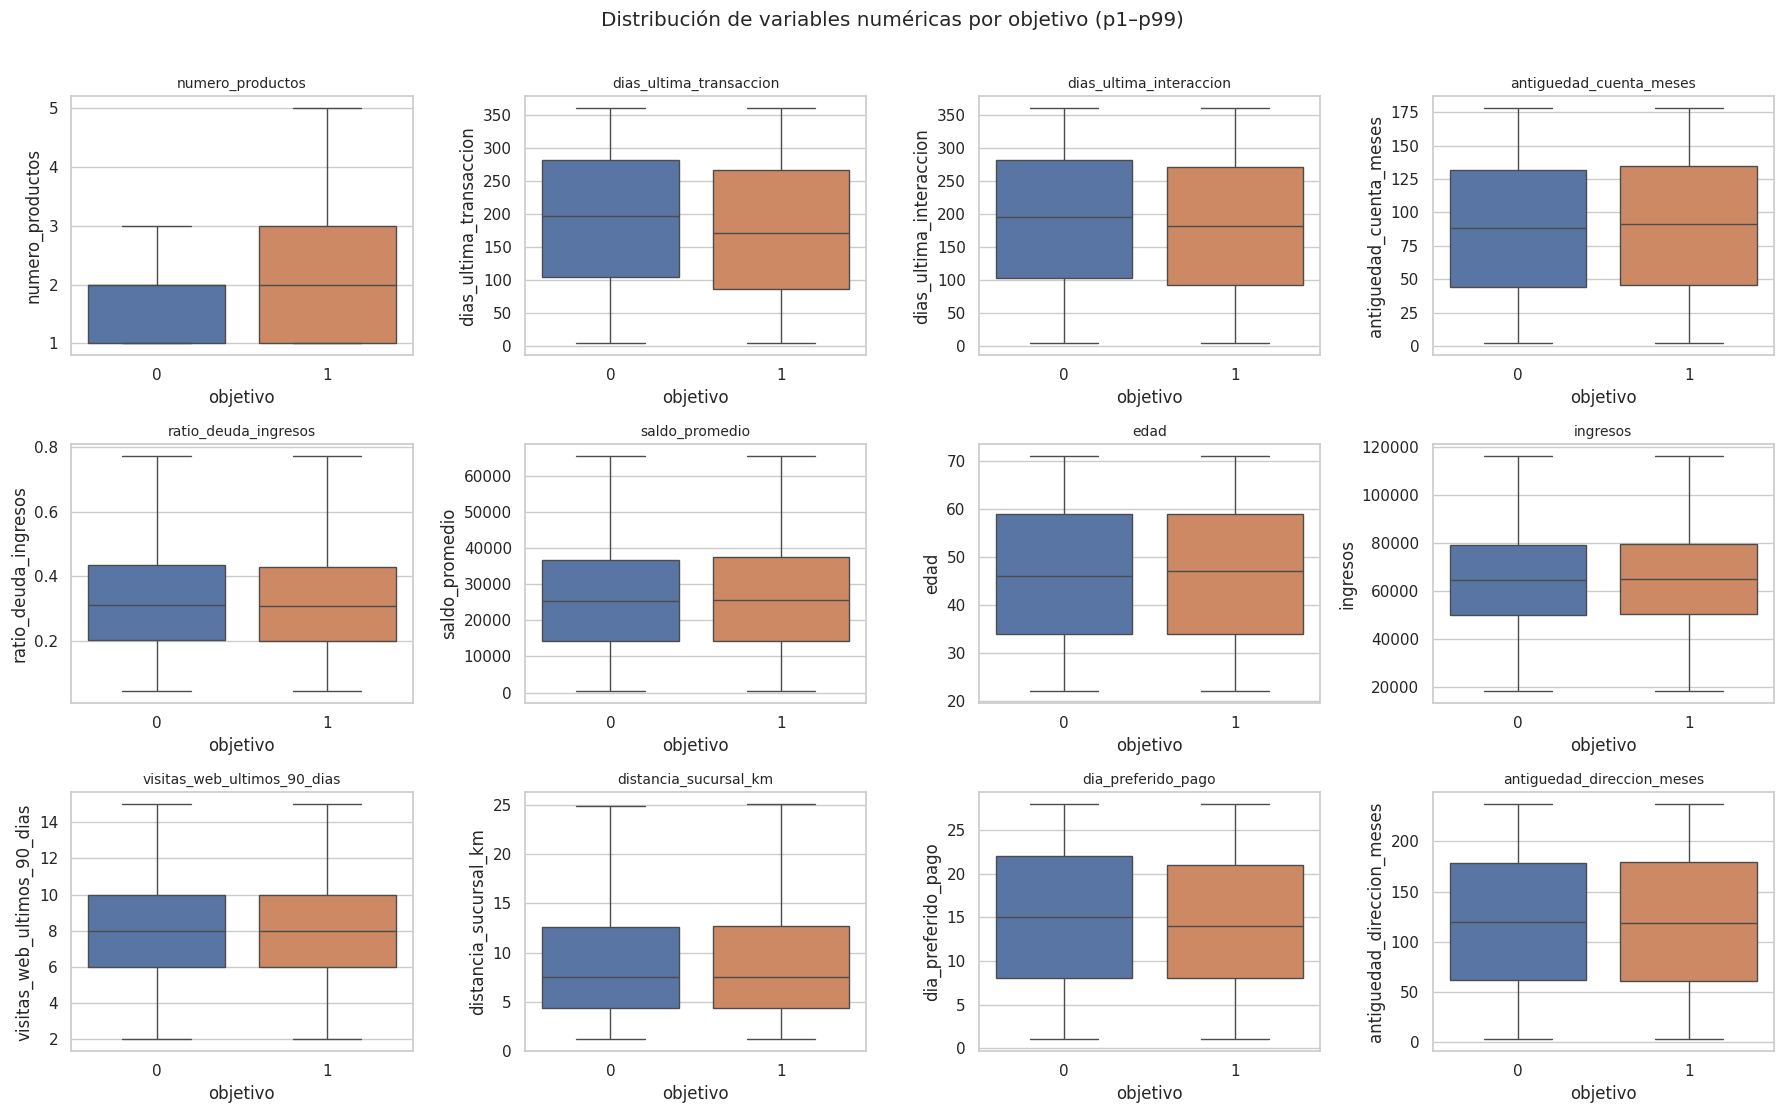

In [8]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11)); axes = axes.ravel()
for ax, c in zip(axes, res_num.variable):
    lo, hi = train[c].quantile([.01, .99]); d = train[(train[c] >= lo) & (train[c] <= hi)]
    sns.boxplot(data=d, x=TARGET, y=c, ax=ax, showfliers=False, palette=['#4C72B0', '#DD8452'])
    ax.set_title(c, fontsize=10)
for ax in axes[len(res_num):]: ax.axis('off')
plt.suptitle('Distribución de variables numéricas por objetivo (p1–p99)', y=1.01); plt.tight_layout(); plt.show()

### Tasa de conversión por deciles de las variables numéricas más relevantes

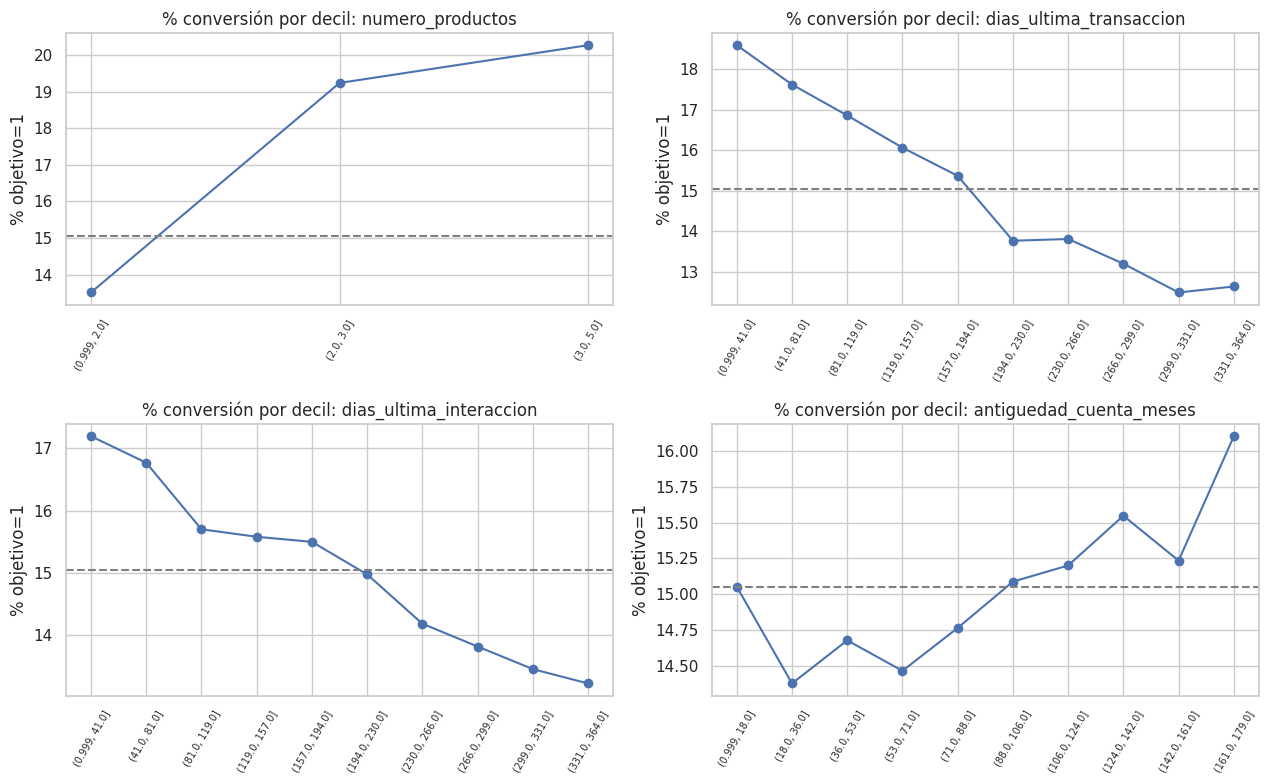

In [9]:
top_num = res_num.variable.head(4).tolist()
fig, axes = plt.subplots(2, 2, figsize=(13, 8)); axes = axes.ravel()
for ax, c in zip(axes, top_num):
    q = min(10, train[c].nunique())
    b = pd.qcut(train[c], q, duplicates='drop')
    t = train.groupby(b)[TARGET].mean() * 100
    ax.plot(range(len(t)), t.values, marker='o'); ax.axhline(train[TARGET].mean() * 100, ls='--', c='gray')
    ax.set_xticks(range(len(t))); ax.set_xticklabels([str(i)[:14] for i in t.index], rotation=60, fontsize=7)
    ax.set_title(f'% conversión por decil: {c}'); ax.set_ylabel('% objetivo=1')
plt.tight_layout(); plt.show()

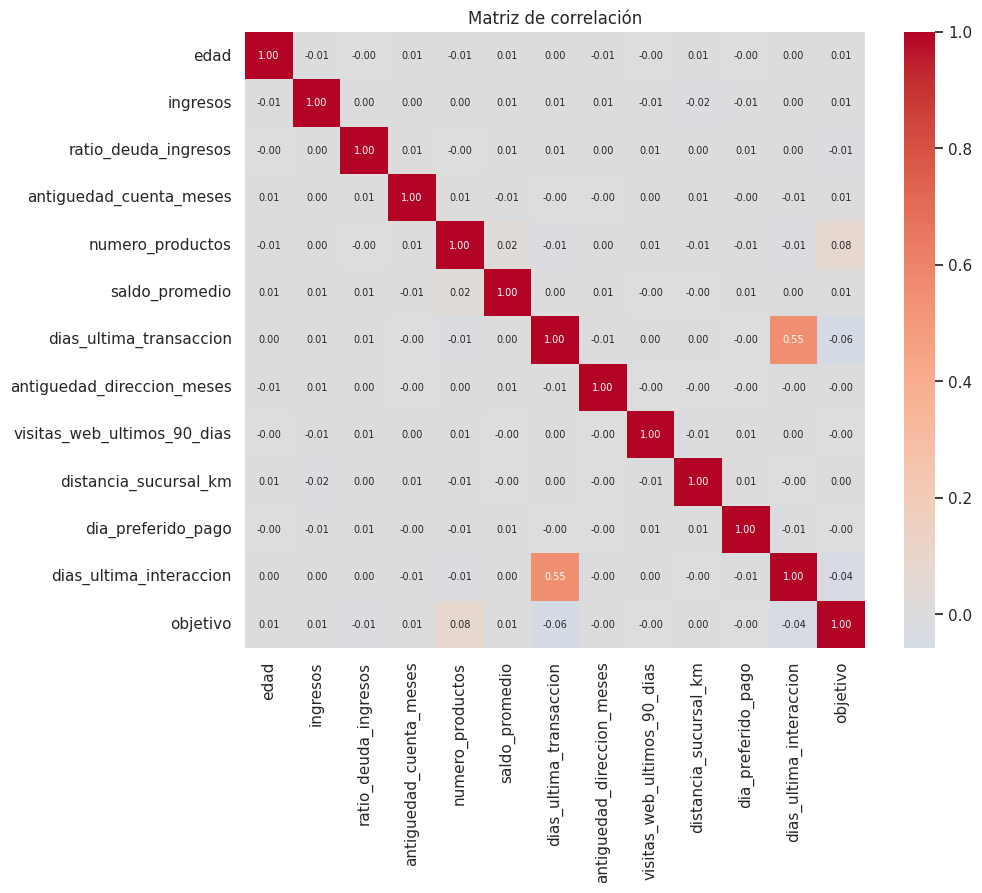

Coincidencia exacta dias_ultima_transaccion == dias_ultima_interaccion (todo train): 54.9%


In [10]:
# Correlación entre numéricas
plt.figure(figsize=(10, 8))
sns.heatmap(train[num_cols + [TARGET]].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 7})
plt.title('Matriz de correlación'); plt.show()
print('Coincidencia exacta dias_ultima_transaccion == dias_ultima_interaccion (todo train): %.1f%%' %
      (100 * (train.dias_ultima_transaccion == train.dias_ultima_interaccion).mean()))

### 4.1 Hallazgo: `dias_ultima_interaccion` cambia de comportamiento con el tiempo


,corr_transaccion_vs_interaccion,%_filas_identicas,AUC_interaccion,AUC_transaccion
202601,1.000,100.000,0.462,0.462
202602,0.907,90.939,0.463,0.470
202603,0.808,81.893,0.453,0.441
202604,0.732,72.823,0.464,0.453
202605,0.638,63.693,0.468,0.459
202606,0.558,54.676,0.477,0.453
202607,0.446,45.660,0.467,0.444
202608,0.366,36.537,0.482,0.449
202609,0.289,27.596,0.480,0.445
202610,0.188,18.433,0.474,0.461


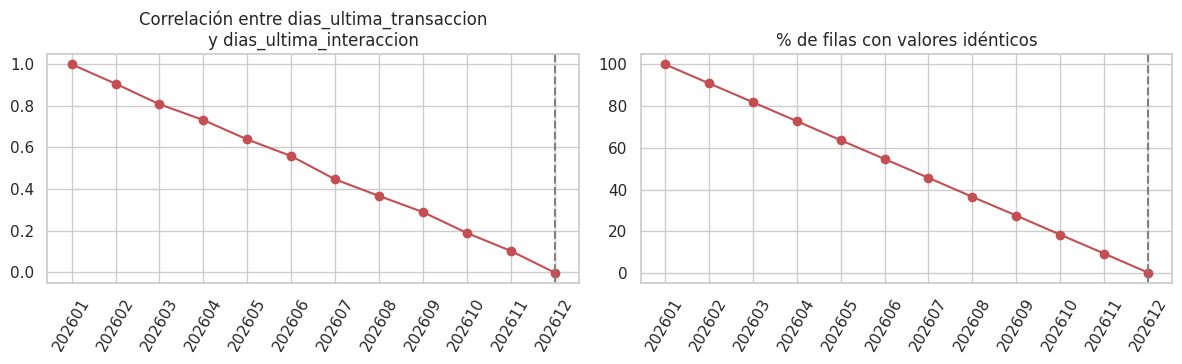

In [11]:
def resumen_mes(d):
    return pd.Series({
        'corr_transaccion_vs_interaccion': d.dias_ultima_transaccion.corr(d.dias_ultima_interaccion),
        '%_filas_identicas': 100 * (d.dias_ultima_transaccion == d.dias_ultima_interaccion).mean(),
        'AUC_interaccion': roc_auc_score(d[TARGET], d['dias_ultima_interaccion']),
        'AUC_transaccion': roc_auc_score(d[TARGET], d['dias_ultima_transaccion'])})

res41 = train.groupby('mes').apply(resumen_mes)
# Diciembre (test): no tiene objetivo, solo se puede medir la relación entre ambas variables
dic = pd.Series({'corr_transaccion_vs_interaccion': test.dias_ultima_transaccion.corr(test.dias_ultima_interaccion),
                 '%_filas_identicas': 100 * (test.dias_ultima_transaccion == test.dias_ultima_interaccion).mean()}, name=202612)
res41 = pd.concat([res41, dic.to_frame().T])
display(res41.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
x = res41.index.astype(int).astype(str)
ax[0].plot(x, res41['corr_transaccion_vs_interaccion'], marker='o', c='#C44E52')
ax[0].set_title('Correlación entre dias_ultima_transaccion\ny dias_ultima_interaccion'); ax[0].tick_params(axis='x', rotation=60)
ax[1].plot(x, res41['%_filas_identicas'], marker='o', c='#C44E52')
ax[1].set_title('% de filas con valores idénticos'); ax[1].tick_params(axis='x', rotation=60)
for a in ax: a.axvline('202612', ls='--', c='gray')
plt.tight_layout(); plt.show()

La variable dias_ultima_interaccion,  que al inicio era idéntica a dias_ultima_transaccion, pierde progresivamente su correlación hasta prácticamente (correlación ≈ 0, coincidencia en solo 0,26 % de las filas).Lo esencial: en el mes de predicción no aporta información útil y se comporta distinto de lo aprendido en el entrenamiento, por lo que fue descartada del modelo para evitar riesgo e inestabilidad.

**Decisión:** La variable dias_ultima_interaccion fue descartada porque perdió correlación con dias_ultima_transaccion hasta volverse ruido en diciembre. En validación temporal no mejoró el desempeño (AUC apenas varió < 0.001) y su comportamiento distinto introducía riesgo e inestabilidad. Por ende, no se utilizó porque no aporta información útil y compromete la robustez del modelo.

## 5. Relación entre `objetivo` y variables categóricas

In [12]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y); chi2 = stats.chi2_contingency(ct)[0]; n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

def woe_iv(df, c):
    g = df.groupby(c)[TARGET].agg(['sum', 'count']); g['bad'] = g['count'] - g['sum']
    d1 = (g['sum'] + .5) / (g['sum'].sum() + .5 * len(g)); d0 = (g['bad'] + .5) / (g['bad'].sum() + .5 * len(g))
    return ((d1 - d0) * np.log(d1 / d0)).sum()

rows = []
for c in cat_cols + bool_cols:
    ct = pd.crosstab(train[c], train[TARGET]); chi2, p, _, _ = stats.chi2_contingency(ct)
    tasa = train.groupby(c)[TARGET].mean()
    rows.append(dict(variable=c, tipo='booleana' if c in bool_cols else 'categórica', n_categorias=train[c].nunique(),
                     tasa_min_pct=tasa.min()*100, tasa_max_pct=tasa.max()*100, rango_pp=(tasa.max()-tasa.min())*100,
                     chi2_p_valor=p, Cramers_V=cramers_v(train[c], train[TARGET]), IV=woe_iv(train, c)))
res_cat = pd.DataFrame(rows).sort_values('IV', ascending=False).reset_index(drop=True)
display(res_cat.round(4))

,variable,tipo,n_categorias,tasa_min_pct,tasa_max_pct,rango_pp,chi2_p_valor,Cramers_V,IV
0,banda_riesgo,categórica,3,8.6985,18.6115,9.9130,0.0000,0.1074,0.1002
1,activo_movil,booleana,2,13.5787,15.8183,2.2396,0.0000,0.0297,0.0071
2,tiene_tarjeta_credito,booleana,2,13.9373,15.4333,1.4960,0.0000,0.0183,0.0027
3,canal_adquisicion,categórica,5,14.1203,15.5753,1.4550,0.0005,0.0134,0.0014
4,ocupacion,categórica,5,14.1011,15.3415,1.2404,0.0246,0.0101,0.0008
5,region,categórica,5,14.5722,15.4847,0.9125,0.2085,0.0073,0.0004
6,tiene_prestamo,booleana,2,14.8129,15.2358,0.4229,0.0521,0.0059,0.0003
7,dispositivo_principal,categórica,4,14.5296,15.1370,0.6073,0.6470,0.0039,0.0001
8,tiene_seguro,booleana,2,15.0155,15.0985,0.0830,0.7145,0.0011,0.0000
9,es_nuevo_cliente,booleana,2,14.9943,15.0598,0.0655,0.8191,0.0007,0.0000


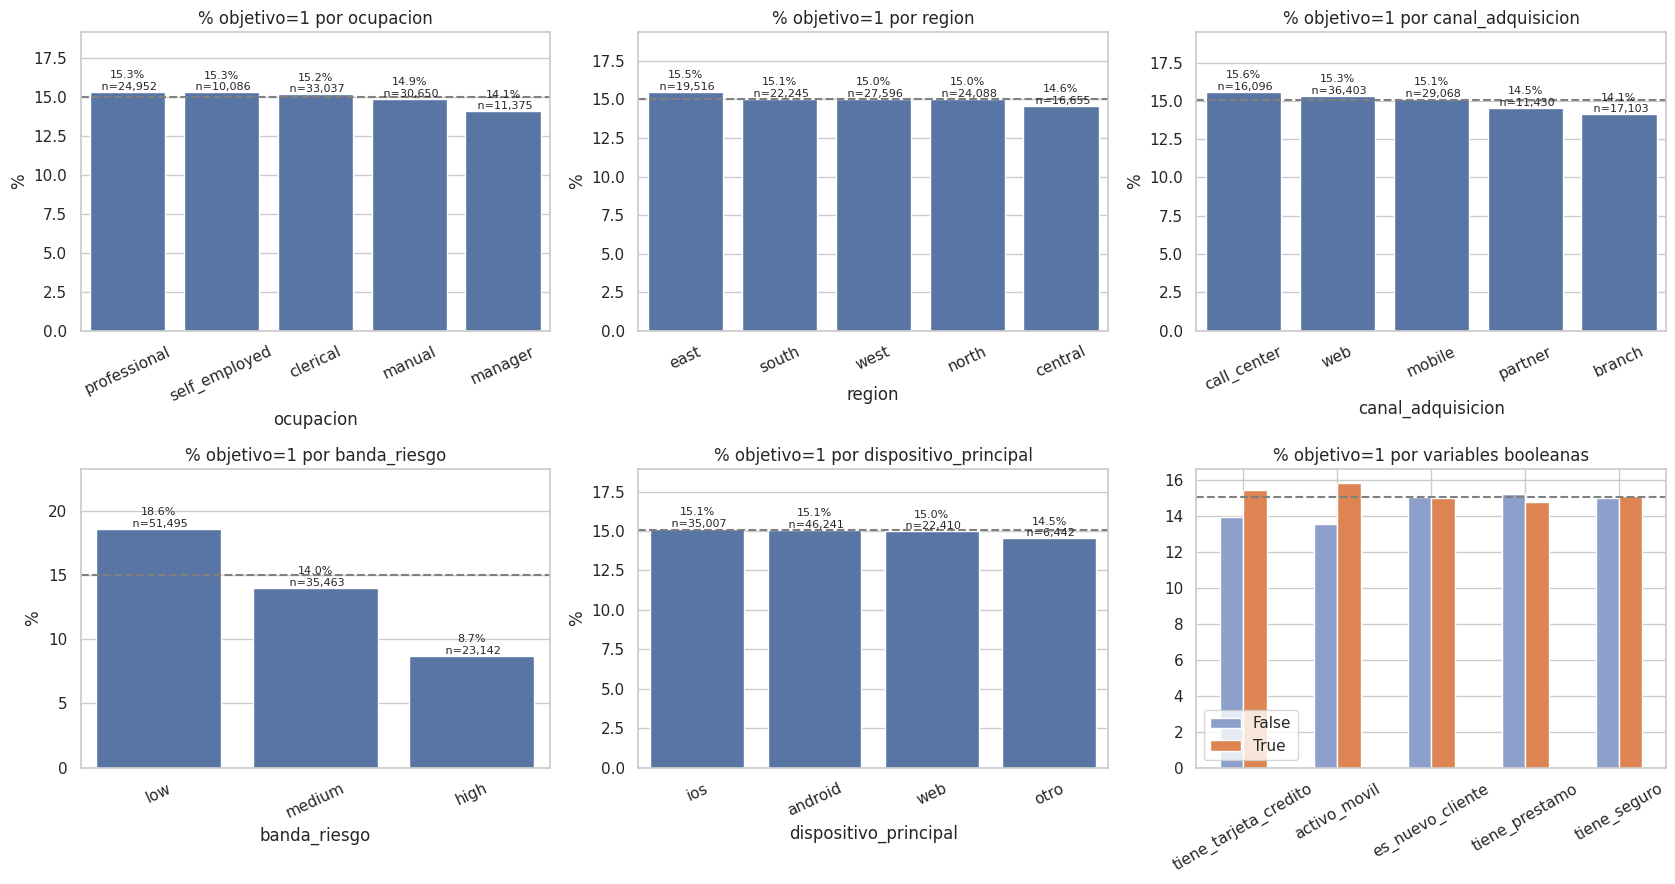

In [13]:
base = train[TARGET].mean() * 100
cols = cat_cols
fig, axes = plt.subplots(2, 3, figsize=(17, 9)); axes = axes.ravel()
for ax, c in zip(axes, cols):
    t = train.groupby(c)[TARGET].agg(['mean', 'size']).sort_values('mean', ascending=False)
    sns.barplot(x=t.index, y=t['mean'] * 100, ax=ax, color='#4C72B0')
    for i, (m_, n_) in enumerate(zip(t['mean'], t['size'])): ax.text(i, m_ * 100, f'{m_*100:.1f}%\n n={n_:,}', ha='center', va='bottom', fontsize=8)
    ax.axhline(base, ls='--', c='gray'); ax.set_title(f'% objetivo=1 por {c}'); ax.set_ylabel('%'); ax.set_ylim(0, t['mean'].max() * 100 * 1.25)
    ax.tick_params(axis='x', rotation=25)
# booleanas en el último panel
tb = pd.DataFrame({c: train.groupby(c)[TARGET].mean() * 100 for c in bool_cols}).T.rename(columns={0: 'False', 1: 'True'})
tb.plot(kind='bar', ax=axes[-1], color=['#8da0cb', '#DD8452']); axes[-1].axhline(base, ls='--', c='gray')
axes[-1].set_title('% objetivo=1 por variables booleanas'); axes[-1].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

## 6. Identificación de variables potencialmente importantes

In [17]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance


train_clean = train.dropna(subset=[TARGET]).reset_index(drop=True)

EXCLUIR = ['dias_ultima_interaccion']
feat_todas = num_cols + cat_cols + bool_cols
feat = [c for c in feat_todas if c not in EXCLUIR]
# Estos serían los niveles de cada categórica (train + test) para que ambos usen las mismas categorías
niveles = {c: sorted(set(train_clean[c].dropna()) | set(test[c].dropna())) for c in cat_cols}

def make_X(df, cols):
    X = df[cols].copy()
    for c in cols:
        if c in cat_cols:
            X[c] = pd.Categorical(X[c], categories=niveles[c])
    return X

def nuevo_modelo(**kw):
    params = dict(max_depth=3, learning_rate=0.03, max_iter=200, early_stopping=False,
                  categorical_features='from_dtype', random_state=42); params.update(kw)
    return HistGradientBoostingClassifier(**params)

tr = train_clean.mes <= 202609; va = ~tr
comparacion = []
for nombre, cols, kw in [('Versión anterior: todas las variables, profundidad 4, 300 iter.', feat_todas, dict(max_depth=4, learning_rate=0.05, max_iter=300)),
                         ('Todas las variables (incluye dias_ultima_interaccion)', feat_todas, {}),
                         ('Sin dias_ultima_interaccion  <- modelo elegido', feat, {})]:
    m_ = nuevo_modelo(**kw).fit(make_X(train_clean[tr], cols), train_clean.loc[tr, TARGET])
    a_ = roc_auc_score(train_clean.loc[va, TARGET], m_.predict_proba(make_X(train_clean[va], cols))[:, 1])
    comparacion.append(dict(modelo=nombre, AUC=a_, Gini=2*a_-1))
display(pd.DataFrame(comparacion).round(4))

X = make_X(train_clean, feat)
mdl = nuevo_modelo().fit(X[tr], train_clean.loc[tr, TARGET])
p = mdl.predict_proba(X[va])[:, 1]
auc = roc_auc_score(train_clean.loc[va, TARGET], p)
print(f'Modelo elegido, validación temporal (oct–nov) -> AUC = {auc:.4f} | Gini = {2*auc-1:.4f}')

# Estabilidad: se repite con otros cortes temporales (entrenar hasta el corte, validar en todos los meses posteriores)
est = []
for corte in [202607, 202608, 202609, 202610]:
    t_ = train_clean.mes <= corte; v_ = ~t_
    m_ = nuevo_modelo().fit(X[t_], train_clean.loc[t_, TARGET])
    a_ = roc_auc_score(train_clean.loc[v_, TARGET], m_.predict_proba(X[v_])[:, 1])
    est.append(dict(entrena_hasta=corte, valida_en=f'{train_clean.loc[v_, "mes"].min()}–{train_clean.loc[v_, "mes"].max()}', AUC=a_, Gini=2*a_-1))
display(pd.DataFrame(est).round(4))

,modelo,AUC,Gini
0,"Versión anterior: todas las variables, profundidad 4, 300 iter.",0.6211,0.2422
1,Todas las variables (incluye dias_ultima_interaccion),0.6251,0.2502
2,Sin dias_ultima_interaccion <- modelo elegido,0.6244,0.2489


Modelo elegido, validación temporal (oct–nov) -> AUC = 0.6244 | Gini = 0.2489


,entrena_hasta,valida_en,AUC,Gini
0,202607,202608–202611,0.6259,0.2519
1,202608,202609–202611,0.6235,0.2470
2,202609,202610–202611,0.6244,0.2489
3,202610,202611–202611,0.6190,0.2381


,caida_AUC,std,Gini_univariado,IV
variable,,,,
banda_riesgo,0.0786,0.0026,NaN,0.1002
numero_productos,0.0345,0.0025,0.1136,NaN
dias_ultima_transaccion,0.0253,0.0028,0.0929,NaN
activo_movil,0.0061,0.0013,NaN,0.0071
tiene_tarjeta_credito,0.0057,0.0010,NaN,0.0027
ratio_deuda_ingresos,0.0041,0.0007,0.0173,NaN
canal_adquisicion,0.0017,0.0005,NaN,0.0014
antiguedad_cuenta_meses,0.0007,0.0007,0.0175,NaN
edad,0.0002,0.0003,0.0112,NaN


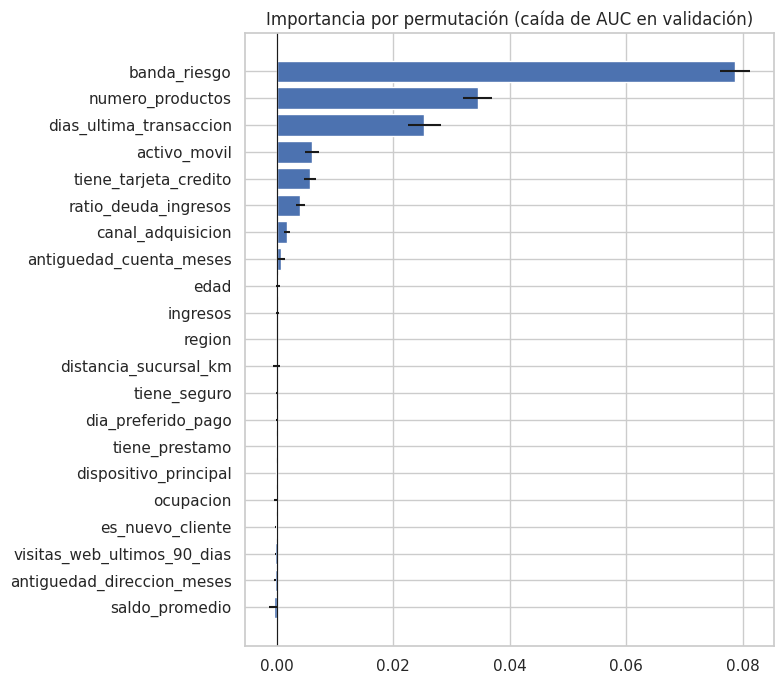

In [18]:
pi = permutation_importance(mdl, X[va], train_clean.loc[va, TARGET], scoring='roc_auc', n_repeats=5, random_state=42, n_jobs=-1)
imp = pd.DataFrame({'variable': feat, 'caida_AUC': pi.importances_mean, 'std': pi.importances_std}).sort_values('caida_AUC', ascending=False)

# ranking combinado
gini_num = res_num.set_index('variable')['Gini_abs']
iv = res_cat.set_index('variable')['IV']
rank = imp.set_index('variable').copy()
rank['Gini_univariado'] = gini_num; rank['IV'] = iv
display(rank.round(4))

plt.figure(figsize=(8, 7))
r = imp.sort_values('caida_AUC')
plt.barh(r.variable, r.caida_AUC, xerr=r['std'], color='#4C72B0'); plt.axvline(0, c='k', lw=.8)
plt.title('Importancia por permutación (caída de AUC en validación)'); plt.tight_layout(); plt.show()

In [16]:
sig = imp[imp.caida_AUC > 2 * imp['std']].variable.tolist()
print('Variables con aporte estadísticamente distinguible de cero (> 2 desv. est.):')
print(sig)

Variables con aporte estadísticamente distinguible de cero (> 2 desv. est.):
['banda_riesgo', 'numero_productos', 'dias_ultima_transaccion', 'activo_movil', 'tiene_tarjeta_credito', 'ratio_deuda_ingresos', 'canal_adquisicion']


### 6.1 Evaluación de mejoras para el modelo
Se exploraron distintas alternativas para mejorar el modelo, usamos solo variables significativas, ajustamos la complejidad, regularización y añadimos una variable histórica por cliente (meses_desde_primera), pero ninguna generó mejoras relevantes. Entonces, el modelo ya estaba cerca del máximo alcanzable con los datos disponibles, dado que la mayoría de las variables son fijas por cliente y no permiten construir indicadores dinámicos entre meses.

In [19]:
# Variable de historia: meses desde la primera aparición del cliente
tr_all = pd.concat([train_clean[['id_cliente', 'mes']], test[['id_cliente', 'mes']]])
idx = lambda m: (m // 100 - 2026) * 12 + m % 100
primera = tr_all.assign(mi=idx(tr_all.mes)).groupby('id_cliente').mi.min()
train_clean['meses_desde_primera'] = idx(train_clean.mes) - train_clean.id_cliente.map(primera)

def eval_cortes(cols, **kw):
    aucs = []
    for corte in [202607, 202608, 202609, 202610]:
        t_ = train_clean.mes <= corte; v_ = ~t_
        m_ = nuevo_modelo(**kw).fit(make_X(train_clean[t_], cols), train_clean.loc[t_, TARGET])
        aucs.append(roc_auc_score(train_clean.loc[v_, TARGET], m_.predict_proba(make_X(train_clean[v_], cols))[:, 1]))
    return aucs

sel7 = ['banda_riesgo', 'numero_productos', 'dias_ultima_transaccion', 'activo_movil', 'ratio_deuda_ingresos', 'tiene_tarjeta_credito', 'canal_adquisicion']
pruebas = [
    ('Modelo elegido (todas sin dias_ultima_interaccion)', feat, {}),
    ('+ meses_desde_primera (historia del cliente)',       feat + ['meses_desde_primera'], {}),
    ('Solo las 7 variables significativas',                 sel7, {}),
    ('Más suave: profundidad 2, 300 iter.',                 feat, dict(max_depth=2, max_iter=300)),
    ('Más lento: 400 iter., lr 0.02',                       feat, dict(max_iter=400, learning_rate=0.02)),
    ('Regularizado: prof. 4, L2=5, min_hoja=100',           feat, dict(max_depth=4, max_iter=150, l2_regularization=5, min_samples_leaf=100)),
]
filas = []
for nombre, cols, kw in pruebas:
    a_ = eval_cortes(cols, **kw)
    filas.append(dict(prueba=nombre, AUC_medio=np.mean(a_), Gini_medio=2 * np.mean(a_) - 1, Gini_peor_corte=2 * min(a_) - 1))
display(pd.DataFrame(filas).round(4))

,prueba,AUC_medio,Gini_medio,Gini_peor_corte
0,Modelo elegido (todas sin dias_ultima_interaccion),0.6232,0.2464,0.2381
1,+ meses_desde_primera (historia del cliente),0.6228,0.2457,0.2370
2,Solo las 7 variables significativas,0.6234,0.2468,0.2368
3,"Más suave: profundidad 2, 300 iter.",0.6210,0.2419,0.2300
4,"Más lento: 400 iter., lr 0.02",0.6230,0.2460,0.2351
5,"Regularizado: prof. 4, L2=5, min_hoja=100",0.6220,0.2440,0.2322


## 7. Explicación de AUC y Gini

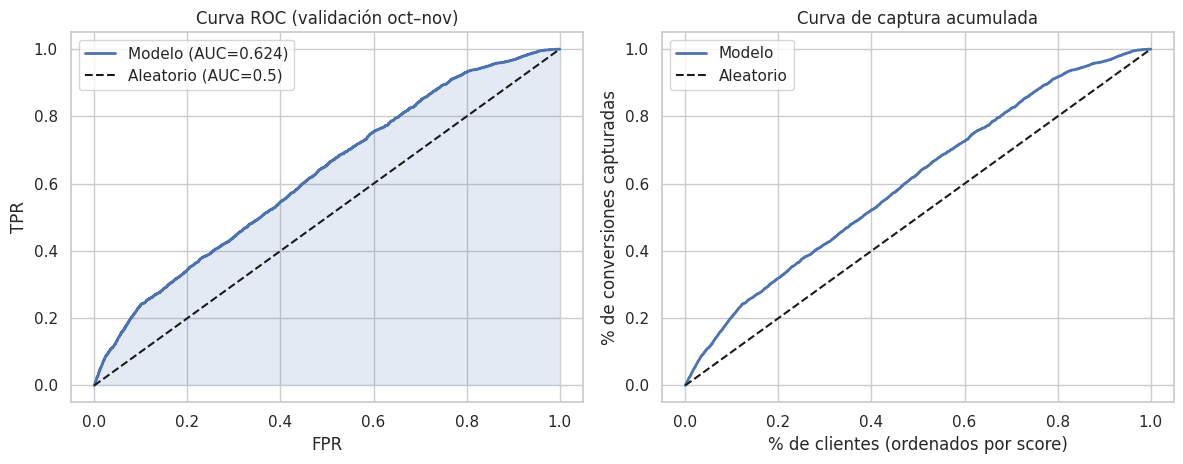

AUC sklearn: 0.6244 | P(score_pos > score_neg) por simulación: 0.6234
Gini = 2*AUC-1 = 0.2489
Al contactar al 10% de clientes con mayor score se captura el 20.4% de las conversiones (azar: 10%).


In [ ]:
# Demostración visual con las predicciones de validación
yv = train_clean.loc[va, TARGET].values
fpr, tpr, _ = roc_curve(yv, p)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
ax[0].plot(fpr, tpr, lw=2, label=f'Modelo (AUC={auc:.3f})'); ax[0].plot([0, 1], [0, 1], 'k--', label='Aleatorio (AUC=0.5)')
ax[0].fill_between(fpr, tpr, alpha=.15); ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR'); ax[0].set_title('Curva ROC (validación oct–nov)'); ax[0].legend()
# Curva de captura acumulada: conversiones capturadas al ordenar por score
o = np.argsort(-p); cum = np.cumsum(yv[o]) / yv.sum(); x = np.arange(1, len(yv) + 1) / len(yv)
ax[1].plot(x, cum, lw=2, label='Modelo'); ax[1].plot([0, 1], [0, 1], 'k--', label='Aleatorio')
ax[1].set_xlabel('% de clientes (ordenados por score)'); ax[1].set_ylabel('% de conversiones capturadas'); ax[1].set_title('Curva de captura acumulada'); ax[1].legend()
plt.tight_layout(); plt.show()

# Verificación: AUC = P(score_pos > score_neg)
rng = np.random.default_rng(0); pos = p[yv == 1]; neg = p[yv == 0]
a = rng.choice(pos, 200000); b = rng.choice(neg, 200000)
print(f'AUC sklearn: {auc:.4f} | P(score_pos > score_neg) por simulación: {(a > b).mean() + 0.5 * (a == b).mean():.4f}')
print(f'Gini = 2*AUC-1 = {2*auc-1:.4f}')
top10 = cum[int(0.1 * len(cum)) - 1]
print(f'Al contactar al 10% de clientes con mayor score se captura el {top10:.1%} de las conversiones (azar: 10%).')

## 8. Comparación entre `train` y `test`


In [ ]:
def psi_num(a, b, bins=10):
    edges = np.unique(np.quantile(a, np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
    pa = np.clip(np.histogram(a, edges)[0] / len(a), 1e-4, None); pb = np.clip(np.histogram(b, edges)[0] / len(b), 1e-4, None)
    return float(((pb - pa) * np.log(pb / pa)).sum())

def psi_cat(a, b):
    set_a = {str(x) for x in a if pd.notna(x)}
    set_b = {str(x) for x in b if pd.notna(x)}
    niv = sorted(set_a | set_b)
    pa = a.astype(str).value_counts(normalize=True).reindex(niv).fillna(0).clip(lower=1e-4)
    pb = b.astype(str).value_counts(normalize=True).reindex(niv).fillna(0).clip(lower=1e-4)
    return float(((pb - pa) * np.log(pb / pa)).sum())

filas = []
for c in num_cols:  filas.append(dict(variable=c, tipo='numérica',   PSI=psi_num(train[c], test[c]), media_train=train[c].mean(), media_test=test[c].mean()))
for c in cat_cols:  filas.append(dict(variable=c, tipo='categórica', PSI=psi_cat(train[c], test[c]), media_train=np.nan, media_test=np.nan))
for c in bool_cols: filas.append(dict(variable=c, tipo='booleana',   PSI=psi_cat(train[c], test[c]), media_train=train[c].mean(), media_test=test[c].mean()))
psi_tab = pd.DataFrame(filas).sort_values('PSI', ascending=False).reset_index(drop=True)
display(psi_tab.round(4))
print('PSI máximo:', round(psi_tab.PSI.max(), 4), '(< 0.1 indica distribución estable)')

print('\nCategorías nuevas en test respecto de train:', {c: sorted({str(x) for x in test[c] if pd.notna(x)} - {str(x) for x in train[c] if pd.notna(x)}) for c in cat_cols})
vistos = test.id_cliente.isin(train.id_cliente)
print(f'Clientes de test que ya aparecían en train: {vistos.mean():.1%} ({vistos.sum():,} de {len(test):,})')
prev = test.id_cliente.map(train.groupby('id_cliente').size()).fillna(0).astype(int)
print('Meses previos observados por cliente de test:'); print(prev.value_counts().sort_index().to_string())

,variable,tipo,PSI,media_train,media_test
0,banda_riesgo,categórica,0.0086,NaN,NaN
1,numero_productos,numérica,0.0028,1.9231,1.8716
2,dias_ultima_transaccion,numérica,0.0020,190.2450,194.3073
3,dias_ultima_interaccion,numérica,0.0019,190.1593,194.3073
4,antiguedad_cuenta_meses,numérica,0.0011,88.8984,89.0168
5,ratio_deuda_ingresos,numérica,0.0010,0.3294,0.3324
6,edad,numérica,0.0007,46.3590,46.4041
7,dispositivo_principal,categórica,0.0007,NaN,NaN
8,antiguedad_direccion_meses,numérica,0.0007,119.9592,120.3067
9,ingresos,numérica,0.0006,65162.4599,65341.7872


PSI máximo: 0.0086 (< 0.1 indica distribución estable)

Categorías nuevas en test respecto de train: {'ocupacion': [], 'region': [], 'canal_adquisicion': [], 'banda_riesgo': [], 'dispositivo_principal': []}
Clientes de test que ya aparecían en train: 81.4% (8,061 de 9,900)
Meses previos observados por cliente de test:
id_cliente
0     1839
1      585
2     1281
3      747
4      889
5      414
6      657
7      631
8      228
9      465
10     201
11    1963


**Interpretación:** Las variables de `test` tienen distribuciones muy parecidas a las de `train` (PSI bajo en todas) y no hay categorías nuevas. Esto es compatible con lo visto en 4.1: `dias_ultima_interaccion` conserva una distribución marginal parecida, pero lo que cambia es **su relación con `dias_ultima_transaccion`**, algo que el PSI por variable no detecta. Por eso conviene revisar también las relaciones entre variables y no solo cada columna por separado.

## 9. Modelo final y archivo de entrega
Rentrenamos el modelo elegido con **todo `train`** (enero–noviembre), se predice `test` (diciembre) y se arma `submission.csv` con el formato exacto de `sample_submission.csv`: columnas `id_cliente, prediccion`, una fila por cada fila de `test`, mismo orden y probabilidades entre 0 y 1.

OK    columnas exactas: id_cliente, prediccion
OK    una fila por cada fila de test.csv
OK    mismos id_cliente y mismo orden que test.csv
OK    mismas filas e ids que sample_submission.csv
OK    sin valores faltantes
OK    prediccion entre 0 y 1
OK    no incluye la columna mes

Archivo guardado: submission.csv


,id_cliente,prediccion
0,2,0.147044
1,3,0.065638
2,7,0.143697
3,10,0.058538
4,11,0.155273


,count,mean,std,min,25%,50%,75%,max
prediccion,9900.0,0.1412,0.0587,0.0191,0.1231,0.1399,0.1577,0.4119


Promedio de la predicción en test: 0.1412 | tasa de conversión histórica: 0.1505


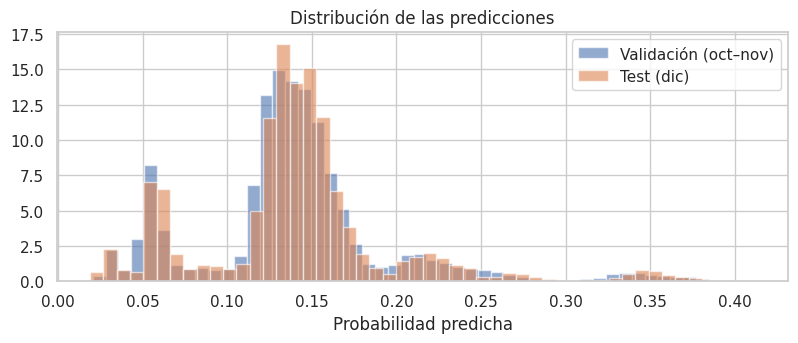

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
mdl_final = nuevo_modelo().fit(make_X(train_clean, feat), train_clean[TARGET])
pred_test = mdl_final.predict_proba(make_X(test, feat))[:, 1]

submission = pd.DataFrame({'id_cliente': test['id_cliente'].values, 'prediccion': pred_test})

# Validamos el formato exigido
validaciones = {
    'columnas exactas: id_cliente, prediccion':           list(submission.columns) == ['id_cliente', 'prediccion'],
    'una fila por cada fila de test.csv':                 len(submission) == len(test),
    'mismos id_cliente y mismo orden que test.csv':       bool((submission.id_cliente.values == test.id_cliente.values).all()),
    'mismas filas e ids que sample_submission.csv':       bool((submission.id_cliente.values == sample.id_cliente.values).all()),
    'sin valores faltantes':                              int(submission.isna().sum().sum()) == 0,
    'prediccion entre 0 y 1':                             bool(submission.prediccion.between(0, 1).all()),
    'no incluye la columna mes':                          'mes' not in submission.columns,
}
for k, v in validaciones.items(): print(('OK   ' if v else 'FALLA'), k)
assert all(validaciones.values()), 'El archivo de entrega no cumple el formato'

submission.to_csv('submission.csv', index=False)
print('\nArchivo guardado: submission.csv')
display(submission.head())
display(submission.prediccion.describe().round(4).to_frame().T)
print(f'Promedio de la predicción en test: {submission.prediccion.mean():.4f} | tasa de conversión histórica: {train_clean[TARGET].mean():.4f}')

plt.figure(figsize=(8, 3.6))
plt.hist(p, bins=50, alpha=.6, density=True, label='Validación (oct–nov)'); plt.hist(pred_test, bins=50, alpha=.6, density=True, label='Test (dic)')
plt.xlabel('Probabilidad predicha'); plt.title('Distribución de las predicciones'); plt.legend(); plt.tight_layout(); plt.show()

try:
    from google.colab import files
    files.download('submission.csv')
except ImportError:
    pass

## 10. Conclusiones

In [21]:
top3_g = res_num[~res_num.variable.isin(EXCLUIR)].head(3)[['variable', 'AUC_univariado']].values.tolist()
print('Prevalencia objetivo=1: %.2f%% (razón %.1f:1)' % (train[TARGET].mean() * 100, n0 / n1))
print('Numéricas con mayor Gini univariado:', [(v, round(a, 3)) for v, a in top3_g])
print('Categóricas/booleanas con mayor IV :', res_cat.head(3)[['variable', 'IV']].round(3).values.tolist())
print('Top 5 por importancia de permutación:', imp.head(5).variable.tolist())
print(f'Modelo elegido (validación temporal oct–nov): AUC={auc:.4f}, Gini={2*auc-1:.4f}')
print(f'Archivo de entrega: submission.csv con {len(submission):,} filas')

Prevalencia objetivo=1: 15.05% (razón 5.6:1)
Numéricas con mayor Gini univariado: [('numero_productos', 0.557), ('dias_ultima_transaccion', 0.454), ('antiguedad_cuenta_meses', 0.509)]
Categóricas/booleanas con mayor IV : [['banda_riesgo', 0.1], ['activo_movil', 0.007], ['tiene_tarjeta_credito', 0.003]]
Top 5 por importancia de permutación: ['banda_riesgo', 'numero_productos', 'dias_ultima_transaccion', 'activo_movil', 'tiene_tarjeta_credito']
Modelo elegido (validación temporal oct–nov): AUC=0.6244, Gini=0.2489
Archivo de entrega: submission.csv con 9,900 filas


**Detalle de los resultados**

- El desempeño del modelo y datos usados nos dice que, la tasa de conversión fue estable (≈15 %) con un desbalance moderado (5.6 : 1), lo que no afectó las métricas. Asimismo,  el modelo de gradient boosting alcanzó un AUC de 0.624 (Gini ≈ 0.249), mostrando resultados consistentes en validaciones temporales y logrando que al contactar al 10 % de clientes con mayor score se capture cerca del 20 % de las conversiones, el doble que al azar.

- Las principales variables relevantes y señales provinieron de banda_riesgo (más conversión en clientes de bajo riesgo), numero_productos (mayor conversión con 3–5 productos) y dias_ultima_transaccion (transacciones recientes aumentan la probabilidad). Otras variables como activo_movil, tarjeta de crédito y ratio deuda/ingresos tuvieron impacto menor, mientras que el resto no mostró aporte significativo.





# **CONCLUSIONES**

- Objetivo y solución: Se entrenó un modelo de gradient boosting con datos de enero a noviembre para predecir conversiones en diciembre de 2026. El archivo de entrega cumplió con el formato exigido.

- El modelo alcanzó un AUC de 0,624 (Gini ≈ 0,249), estable en validaciones temporales. Contactando al 10 % de clientes con mayor puntaje se capturó cerca del 20 % de las conversiones.

- Variables relevantes: Las principales señales provienen de banda_riesgo, numero_productos y dias_ultima_transaccion. Otras variables aportaron marginalmente y varias no mostraron efecto.

- Decisiones metodológicas: Se descartó dias_ultima_interaccion por degradarse y convertirse en ruido; se validó en el tiempo y no al azar; no se aplicó remuestreo por desbalance moderado; y se comprobó que diciembre es consistente con el entrenamiento (PSI = 0,009).

- Límite y aplicación: Pruebas adicionales no mejoraron el rendimiento, indicando que el modelo está cerca del máximo posible con los datos. En negocio, permite focalizar campañas en clientes de bajo riesgo, con más productos y transacciones recientes, logrando el doble de conversiones frente a una estrategia aleatoria.